In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

In [2]:
df = pd.read_csv("olist_cleaned.csv")
display(df.head())
display(df.info())

,product_category_name,product_id,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,...,payment_installments,payment_value,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,utilidades_domesticas,c8e7c2ef329fcda4a233e7e2f8bb8b7d,00310b0c75bb13015ec4d82d341865a4,0dad07848c618cc5a4679a1bfe1db8d2,canceled,2018-08-15 14:29:08,2018-08-15 15:04:25,NaN,NaN,2018-08-29,...,2.0,55.28,58.0,1245.0,1.0,200.0,16.0,12.0,11.0,housewares
1,utilidades_domesticas,08279c494018541f71443c07d77560f8,0032d07457ae9c806c79368d7d9ce96b,d356c20816dc75a309628b5c17d89468,delivered,2018-03-10 18:53:06,2018-03-10 19:48:19,2018-03-13 17:16:42,2018-04-29 21:08:59,2018-04-17,...,2.0,186.19,48.0,688.0,2.0,3150.0,43.0,27.0,27.0,housewares
2,beleza_saude,9545d45c37449ccbc376de3a04c66e71,0045e3085f083f0f38d24bb3f22e6593,eb729faa993caad20442243265804a7c,delivered,2017-08-10 16:13:36,2017-08-11 07:15:16,2017-08-16 18:27:40,2017-08-29 20:03:08,2017-08-30,...,3.0,130.74,39.0,1749.0,1.0,1350.0,27.0,9.0,18.0,health_beauty
3,esporte_lazer,19421075ae0b585f2dc13ff149e2119d,0079bca8e89bd52fdb87408e4f3fb94d,137f50d5bfbcfb9578c50605cc9adb16,delivered,2018-05-03 18:55:20,2018-05-05 03:33:43,2018-05-07 11:10:00,2018-05-08 20:58:26,2018-05-18,...,1.0,57.29,32.0,1797.0,1.0,150.0,16.0,16.0,11.0,sports_leisure
4,moveis_decoracao,e819fddd6622f30e872bfc89471c1408,007ff0b0f79be782f633fc3b18cbe337,fc021f2dd664b49455528422c77b6aab,delivered,2018-02-03 17:46:53,2018-02-03 20:10:10,2018-02-06 18:28:37,2018-02-14 20:27:04,2018-03-02,...,1.0,55.11,60.0,772.0,1.0,650.0,16.0,15.0,13.0,furniture_decor


<class 'pandas.DataFrame'>
RangeIndex: 118434 entries, 0 to 118433
Data columns (total 31 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   product_category_name          117604 non-null  str    
 1   product_id                     117604 non-null  str    
 2   order_id                       118434 non-null  str    
 3   customer_id                    118434 non-null  str    
 4   order_status                   118434 non-null  str    
 5   order_purchase_timestamp       118434 non-null  str    
 6   order_approved_at              118258 non-null  str    
 7   order_delivered_carrier_date   116360 non-null  str    
 8   order_delivered_customer_date  115037 non-null  str    
 9   order_estimated_delivery_date  118434 non-null  str    
 10  customer_unique_id             118434 non-null  str    
 11  customer_zip_code_prefix       118434 non-null  int64  
 12  customer_city                  118434 non

None

In [3]:
df.describe(include='all')
df.isnull().sum()

product_category_name             830
product_id                        830
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 176
order_delivered_carrier_date     2074
order_delivered_customer_date    3397
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                     830
seller_id                         830
shipping_limit_date               830
price                             830
freight_value                     830
payment_sequential                  3
payment_type                        3
payment_installments                3
payment_value                       3
product_name_lenght              2528
product_description_lenght       2528
product_photos_qty               2528
product_weig

In [4]:
df = df.dropna(subset=[
    "product_id",
    "order_item_id",
    "seller_id",
    "price",
    "freight_value"
])

df = df.dropna(subset=["order_approved_at"])

# Fill categorical columns
df["product_category_name"] = df["product_category_name"].fillna("Unknown")
df["product_category_name_english"] = df["product_category_name_english"].fillna("Unknown")

df["payment_type"] = df["payment_type"].fillna(df["payment_type"].mode()[0])

numeric_cols = [
    "payment_sequential",
    "payment_installments",
    "payment_value",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()


product_category_name               0
product_id                          0
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                   0
order_delivered_carrier_date     1245
order_delivered_customer_date    2567
order_estimated_delivery_date       0
customer_unique_id                  0
customer_zip_code_prefix            0
customer_city                       0
customer_state                      0
order_item_id                       0
seller_id                           0
shipping_limit_date                 0
price                               0
freight_value                       0
payment_sequential                  0
payment_type                        0
payment_installments                0
payment_value                       0
product_name_lenght                 0
product_description_lenght          0
product_photos_qty                  0
product_weig

In [5]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col])

df["LateDelivery"] = np.where(
    df["order_delivered_customer_date"] >
    df["order_estimated_delivery_date"],
    1,
    0
)

df = df.dropna(subset=["order_delivered_customer_date"])
df["LateDelivery"].value_counts()


LateDelivery
0    105995
1      9027
Name: count, dtype: int64

In [6]:
df["ApprovalTime"] = (
    df["order_approved_at"] -
    df["order_purchase_timestamp"]
).dt.days

df["ProductVolume"] = (
    df["product_length_cm"] *
    df["product_height_cm"] *
    df["product_width_cm"]
)

df["OrderMonth"] = df["order_purchase_timestamp"].dt.month

df["OrderDay"] = df["order_purchase_timestamp"].dt.day



In [7]:
features = [
    "price", "freight_value",
    "payment_value", "payment_installments",
    "product_weight_g", "ProductVolume",
    "ApprovalTime", "OrderMonth",
    "OrderDay", "customer_state",
    "payment_type", "product_category_name_english"
]

target = "LateDelivery"

In [8]:
categorical = [
    "customer_state",
    "payment_type",
    "product_category_name_english"
]

encoder = LabelEncoder()

for col in categorical:
    df[col] = encoder.fit_transform(df[col].astype(str))

In [9]:
X = df[features]

y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [10]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [11]:
y_pred = rf.predict(X_test)

In [12]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)

Accuracy: 0.9220169528363399


In [13]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     21200
           1       1.00      0.01      0.01      1805

    accuracy                           0.92     23005
   macro avg       0.96      0.50      0.49     23005
weighted avg       0.93      0.92      0.89     23005



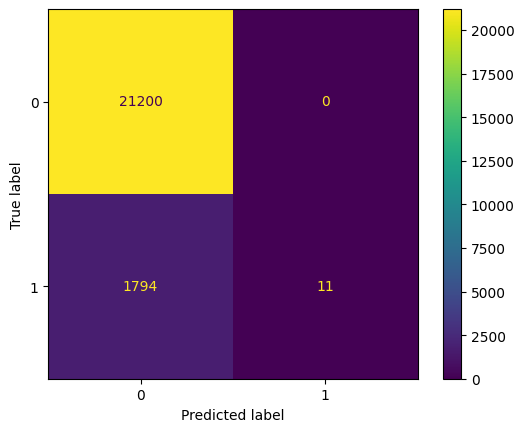

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.show()

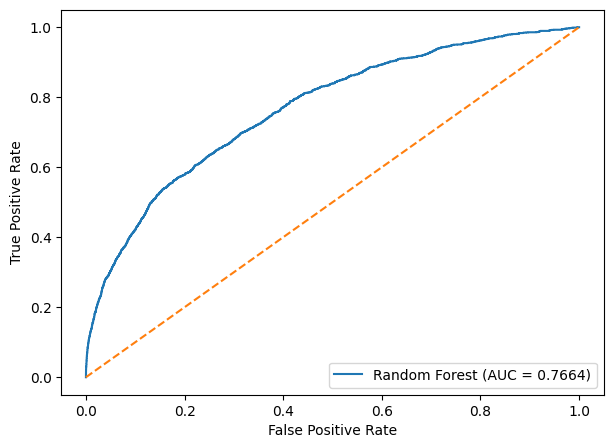

In [15]:
y_prob = rf.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "--")

plt.legend(loc="lower right")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.show()

In [16]:
param_grid = {
    "n_estimators": [100],
    "max_depth": [10, None],
    "min_samples_split": [2]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
print(grid.best_params_)

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


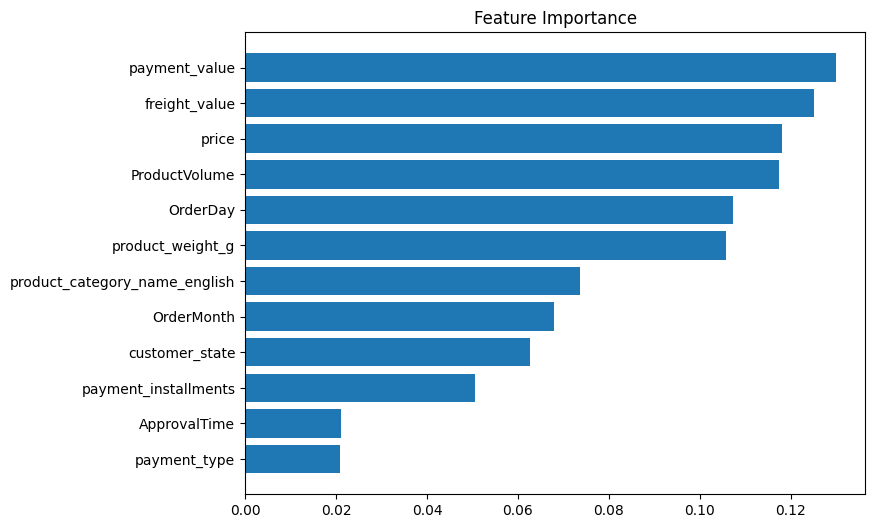

In [17]:
importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":best_rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)
plt.figure(figsize=(8,6))

plt.barh(

    importance["Feature"],

    importance["Importance"]

)

plt.gca().invert_yaxis()

plt.title("Feature Importance")

plt.show()

In [18]:
predictions = X_test.copy()

predictions["Actual"] = y_test.values

predictions["Predicted"] = best_rf.predict(X_test)

predictions.to_csv(
    "customer_predictions.csv",
    index=False
)

In [19]:
new_data = X_test.iloc[[0]]

prediction = best_rf.predict(new_data)

probability = best_rf.predict_proba(new_data)

print("Actual Label:", y_test.iloc[0])
print("Predicted Label:", prediction[0])
print("Prediction Probability:", probability)

Actual Label: 0
Predicted Label: 0
Prediction Probability: [[0.91 0.09]]
